In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. 데이터 읽어와서 출력

In [4]:
csv_path = "C:/Users/SSAFY/Downloads/NFLX.csv"

df = pd.read_csv(csv_path)

df

,Date,Open,High,Low,Close,Adj Close,Volume
0,2018-02-05,262.000000,267.899994,250.029999,254.259995,254.259995,11896100
1,2018-02-06,247.699997,266.700012,245.000000,265.720001,265.720001,12595800
2,2018-02-07,266.579987,272.450012,264.329987,264.559998,264.559998,8981500
3,2018-02-08,267.079987,267.619995,250.000000,250.100006,250.100006,9306700
4,2018-02-09,253.850006,255.800003,236.110001,249.470001,249.470001,16906900
...,...,...,...,...,...,...,...
1004,2022-01-31,401.970001,427.700012,398.200012,427.140015,427.140015,20047500
1005,2022-02-01,432.959991,458.480011,425.540009,457.130005,457.130005,22542300
1006,2022-02-02,448.250000,451.980011,426.480011,429.480011,429.480011,14346000
1007,2022-02-03,421.440002,429.260010,404.279999,405.600006,405.600006,9905200


### 데이터 설명
  - `Date`: 주식 가격 데이터가 기록된 특정 날짜
  - `Open`: 시가
  - `High`: 고가
  - `Low`: 저가
  - `Close`: 종가
  - `Volume`: 거래량

In [5]:
df.dtypes

Date             str
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object

# 2. 데이터 전처리
Netflix 주가 데이터(NFLX.csv)를 Pandas를 사용해 DataFrame으로 읽어온다.

이 때, 'Date', 'Open','High', 'Low', 'Close' 필드만 선택한다.

In [6]:
df = pd.read_csv(csv_path, usecols = range(5))

df

,Date,Open,High,Low,Close
0,2018-02-05,262.000000,267.899994,250.029999,254.259995
1,2018-02-06,247.699997,266.700012,245.000000,265.720001
2,2018-02-07,266.579987,272.450012,264.329987,264.559998
3,2018-02-08,267.079987,267.619995,250.000000,250.100006
4,2018-02-09,253.850006,255.800003,236.110001,249.470001
...,...,...,...,...,...
1004,2022-01-31,401.970001,427.700012,398.200012,427.140015
1005,2022-02-01,432.959991,458.480011,425.540009,457.130005
1006,2022-02-02,448.250000,451.980011,426.480011,429.480011
1007,2022-02-03,421.440002,429.260010,404.279999,405.600006


# 3. 날짜 필터링
2021년 이후 데이터 필터링 

In [7]:
df_after_2021 = df[df["Date"] >= "2021-01-01"]

df_after_2021

,Date,Open,High,Low,Close
733,2021-01-04,539.000000,540.799988,515.090027,522.859985
734,2021-01-05,521.549988,526.780029,515.890015,520.799988
735,2021-01-06,511.970001,513.099976,499.500000,500.489990
736,2021-01-07,508.279999,516.440002,506.420013,508.890015
737,2021-01-08,511.309998,513.239990,504.510010,510.399994
...,...,...,...,...,...
1004,2022-01-31,401.970001,427.700012,398.200012,427.140015
1005,2022-02-01,432.959991,458.480011,425.540009,457.130005
1006,2022-02-02,448.250000,451.980011,426.480011,429.480011
1007,2022-02-03,421.440002,429.260010,404.279999,405.600006


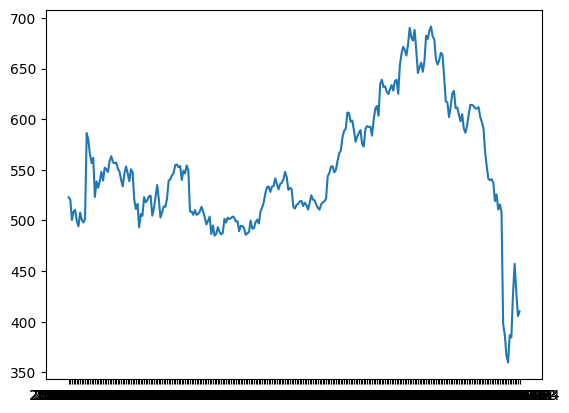

In [8]:
plt.plot(df_after_2021["Date"], df_after_2021["Close"])

plt.show()

# 4. 최고/최저 종가 추출
2021년 이후 데이터에서
종가(Close)의 최대/최소 값을 추출 

In [9]:
large = max(df_after_2021["Close"])
small= min(df_after_2021["Close"])
print(large)
print(small)

691.690002
359.700012


# 5. 월별 평균 종가 계산
2021년 이후 데이터를 월별로
그룹화하여 평균 종가를 계산하여
시각화

In [10]:
# date의 열을  datetime으로변환
df_after_2021['Date'] = pd.to_datetime(df_after_2021['Date'])

df_year = df_after_2021.groupby(df_after_2021["Date"].dt.to_period("M"))["Close"].mean().reset_index()
df_year.rename(columns = { "Close" : "Close_Mean"}, inplace = True)
df_year

,Date,Close_Mean
0,2021-01,526.816845
1,2021-02,548.959999
2,2021-03,518.123482
3,2021-04,533.136662
4,2021-05,496.714497
5,2021-06,503.324091
6,2021-07,528.653330
7,2021-08,532.346817
8,2021-09,590.795239
9,2021-10,642.202849


# 6. 월별 최고/최저/종가 시각화
2022년 이후 데이터를 바탕으로 3가지
지표를 하나의 그래프에 시각화 

In [11]:
# 최고는 max, 최저는 min , 종가는 mean 사용

df_new_year = df_after_2021.groupby(df_after_2021["Date"].dt.to_period("M")).agg({
    'Close' : ["max", "min", "mean"]}).reset_index()

df_new_year.columns = ["Date", "Max", "Min", "Mean"]
df_new_year

,Date,Max,Min,Mean
0,2021-01,586.340027,494.250000,526.816845
1,2021-02,563.590027,533.780029,548.959999
2,2021-03,550.640015,493.329987,518.123482
3,2021-04,555.309998,505.549988,533.136662
4,2021-05,509.109985,484.980011,496.714497
5,2021-06,533.500000,485.809998,503.324091
6,2021-07,547.950012,511.769989,528.653330
7,2021-08,569.190002,510.720001,532.346817
8,2021-09,610.340027,573.140015,590.795239
9,2021-10,690.309998,603.349976,642.202849


In [12]:
# Date가 period[M]으로 월단위 타입이므로 x축에 작성이 안되서 datetime으로 변환 하기
df_new_year['Date'] = df_new_year['Date'].dt.to_timestamp()

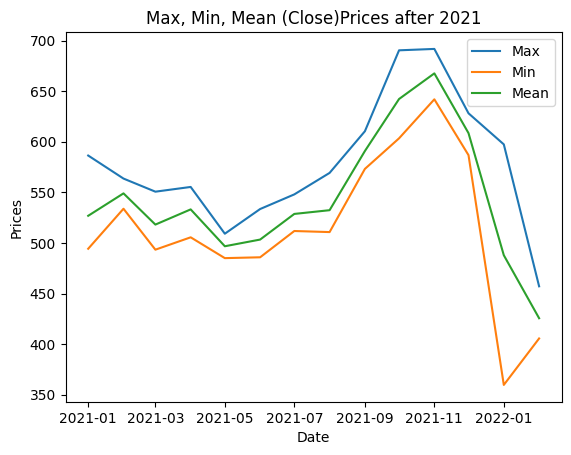

In [13]:
plt.plot(df_new_year["Date"], df_new_year["Max"], label = "Max")
plt.plot(df_new_year["Date"], df_new_year["Min"], label = "Min")
plt.plot(df_new_year["Date"], df_new_year["Mean"], label = "Mean")

plt.title("Max, Min, Mean (Close)Prices after 2021")

plt.xlabel("Date")
plt.ylabel("Prices")

plt.legend()

plt.show()

# 7. 주가 예측 프롬포트 작성(심화)
생성형 AI에게 적절한 프롬프트를
설계하고 주가에 대한 예측 결과를
도출